## Conventions: 

+ TN is one-based. 
+ Epochs use [start, stop) (the stop value is excluded). 
+ Targets are centred so each participant’s repeated target is 0°. 


** Keep updating this ABBY **

# Import 

In [30]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from pre_processing import pre_process, json_decode


sns.set_palette("hsv_r")

# This affects things like the size of the labels, lines, and other elements of the plot, but not the overall style. 
# The base context is “notebook”, and the other contexts are “paper”, “talk”, and “poster”, which are version of 
# the notebook parameters scaled by .8, 1.3, and 1.6, respectively.
sns.set_context("talk")

%config Inline.figure_format = 'retina'
%matplotlib inline

# Constants

In [31]:
# measurements: angle at 40 ms, 100 ms, peak velocity, and movement end (10 cm)
ANGLE_COLS = ["theta_40", "theta_100", "theta_pv", "theta_end"]
ANGLE_LABELS = {
    "theta_40": "40 ms", 
    "theta_100": "100 ms",
    "theta_pv": "Peak velocity", 
    "theta_end": "Movement end",
}

# One-based trial numbering. Epochs remain half-open: start <= TN < stop.
# Allows for easy calculation of the number of trials per phase 
# baseline: 16, repulse: 700, UDL: 864
EPOCHS = {
    "baseline": (1, 17),
    "repulse": (17, 717),
    "repulse_clean": (117, 717),
    "udl_baseline_FB": (717, 787),
    "udl_baseline_noFB": (787, 857),
    "udl_baseline_noFB_second_half": (822, 857),
    "udl": (857, 1721),
    "udl_full": (717, 1721),
}

# Update as participants are added  
CENTRAL_TARGET = {
    10: 120,
    11: 60,
    12: 120,
    13: 60, 
    14: 120, 
    15: 60
}

SUBJECT_IDS = ["671105437",
               "972519978",
               "854984556", 
               "651255439", 
               "180791054", 
               "986564017"]    

PARTICIPANTS = sorted(CENTRAL_TARGET)

# Read in Data 

In [32]:
# File paths for each experimental condition 
# Order must match SUBJECT_IDS; no need to manually add every time 

file_paths_baseline = [f"../data/csv_files/{sn:02d}_baseline.csv" for sn in PARTICIPANTS]
file_paths_repulse = [f"../data/csv_files/{sn:02d}_repulse.csv"  for sn in PARTICIPANTS]
file_paths_udl = [f"../data/csv_files/{sn:02d}_udl.csv"      for sn in PARTICIPANTS]


# Load CSV files & label condition
df_baseline_raw = pre_process(file_paths_baseline, SUBJECT_IDS)
df_repulse_raw = pre_process(file_paths_repulse, SUBJECT_IDS)
df_udl_raw = pre_process(file_paths_udl, SUBJECT_IDS)

df_baseline_raw['phase'] = 'baseline'
df_repulse_raw['phase'] = 'repulse'
df_udl_raw['phase'] = 'udl'

# Combine all conditions into a single dataset
df = pd.concat([df_baseline_raw, df_repulse_raw, df_udl_raw]).reset_index(drop=True)

# Add 9 to each subject number (starting at SN 10)
df["SN"] = df["SN"].astype(int) + 9

# Reset the trial number column that resets for each subject
df["TN"] = df.groupby("SN").cumcount() + 1
df

,SN,TN,target_angle,probe,feedback,reach_feedback,rt,mt,peak_vel,theta_40,theta_100,theta_pv,theta_end,Subject ID,phase
0,10,1,120,0,0,too early,0.464,NaN,45.810251,17.062466,10.102503,9.367951,2.511211,671105437,baseline
1,10,2,30,0,0,good reach,0.977,0.197,54.162542,3.119648,4.387282,4.553708,5.664619,671105437,baseline
2,10,3,90,0,0,good reach,0.889,0.177,61.096475,16.767686,13.632011,13.527260,10.013021,671105437,baseline
3,10,4,60,0,0,good reach,0.897,0.261,42.529000,2.366674,6.091430,3.324203,-0.981532,671105437,baseline
4,10,5,180,0,0,good reach,0.903,0.205,51.701278,-4.407044,-4.137273,-3.447047,-0.133353,671105437,baseline
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10315,15,1716,60,0,0,good reach,0.730,0.139,78.995769,17.359197,8.695934,8.022811,4.743868,986564017,udl
10316,15,1717,60,0,0,good reach,0.637,0.338,39.062225,7.151643,9.124804,8.003247,4.433365,986564017,udl
10317,15,1718,330,1,0,good reach,0.577,0.158,67.265331,13.312421,10.733778,10.524808,10.254746,986564017,udl
10318,15,1719,60,0,0,good reach,0.668,0.143,75.971195,5.329083,3.223054,3.772995,0.420885,986564017,udl


# Define Functions 

In [33]:
def circ_dist(ang1, ang2):
    '''
    Signed angular difference, wrapped from -180 to 180 
    '''
    return (ang1 - ang2 + 180) % 360 - 180


def N_finder(data, N_minus_targ = 0):
    '''
    Trial N where the immediately preceding *unfiltered* trial targeted N_minus_targ.
    '''
    # shift() moves target_angle down one row, so each trial (N) is associated with the target angle of the preceding trial (N-1)
    previous_target = data.sort_values(["SN", "TN"]).groupby("SN")["target_angle"].shift()
    # Select trials (N) where the previous trial's target angle equals N_minus_targ
    return data.loc[previous_target == N_minus_targ].copy()


def calculate_se_index(df, y_col):
    """
    calculate the sequential effect (SE) index per participant 
    POSITIVE SE Index = attractive bias (UDL)
    NEGATIVE SE Index = repulsive bias (REPULSE)

    parameters: 
    df : DataFrame; data to calculate SE index from
    y_col : str; column containing corrected bias

    output: 
    df with the SE index per participant 
    """
    negative_mean = df.loc[df["target_angle_diff"] < 0].groupby("SN")[y_col].mean()
    positive_mean = df.loc[df["target_angle_diff"] > 0].groupby("SN")[y_col].mean()

    return negative_mean - positive_mean 


def epoch_mask(data, name):
    start, stop = EPOCHS[name]
    return (data["TN"] >= start) & (data["TN"] < stop)

## Data Wrangling 

In [34]:
# Shift target angles so each participant's central target = 0°
df["target_angle_original"] = df["target_angle"]
df["target_angle"] = circ_dist(df["target_angle_original"], df["SN"].map(CENTRAL_TARGET)).round()

# Compute current-target minus previous-target angle (delta target angle) 
# NOTES:
# 1) CW is negative, CCW is positive 
# 2) Keep the first trial of each block as NA
df["target_angle_diff"] = np.nan
for block in ["repulse", "udl_full"]:
    mask = epoch_mask(df, block)
    previous_angle = df.loc[mask].groupby("SN")["target_angle"].shift()
    df.loc[mask, "target_angle_diff"] = circ_dist(df.loc[mask, "target_angle"], previous_angle)

df["target_angle_diff"] = df["target_angle_diff"].round().astype("Int64")

# Reach filter (COULD CHANGE DEPENDING ON THE STRICTNESS)
good_reach = (
    # (df["reach_feedback"] == "good reach") &
    # (df["rt"] > 0.5) &
    (df["theta_pv"].abs() < 60)
)

# Calculate a separate intrinsic bias (mean reach-target) and corrected bias for EACH angle.
for condition, baseline_block in [("repulse", "repulse_clean"),("udl", "udl_baseline_noFB"),]:
    reference = df.loc[epoch_mask(df, baseline_block) & (df["theta_pv"].abs() < 60)]
    means = reference.groupby(["SN", "target_angle"])[ANGLE_COLS].mean()
    means = means.rename(columns={col: f"bias_{condition}_{col}" for col in ANGLE_COLS})
    df = df.join(means, on=["SN", "target_angle"])

    for angle in ANGLE_COLS:
        df[f"corrected_bias_{condition}_{angle}"] = circ_dist(
            df[angle], df[f"bias_{condition}_{angle}"]
        )

# Repulse & UDL DataFrames 

In [35]:
## REPULSE 
df_repulse_all = df.loc[epoch_mask(df, "repulse_clean")].copy()
df_repulse = df_repulse_all.loc[good_reach.loc[df_repulse_all.index] &(df_repulse_all["target_angle_diff"].abs() <= 90)].copy()

## UDL 
df_udl_all = df.loc[epoch_mask(df, "udl")].copy()
df_udl = df_udl_all.loc[good_reach.loc[df_udl_all.index]].copy()

# First select probes where N-1 was the central target (0 degrees).
# Use ALL UDL trials for N_finder, not the quality-filtered df_udl.
df_udl_candidates = N_finder(df_udl_all, N_minus_targ=0)
df_udl_candidates = df_udl_candidates.loc[df_udl_candidates["probe"] == 1].copy()

df_udl_constrained = df_udl_candidates.loc[good_reach.loc[df_udl_candidates.index]].copy()

# Trial Counts 

#### wait double check ... repulse dropped should not be that high.... JK its bc we constaiend the workspace to -90 to +90 

In [36]:
# Repulse trials that pass the target-angle-change criterion
df_repulse_amgle_constrained = df_repulse_all.loc[df_repulse_all["target_angle_diff"].abs() <= 90]

trial_counts = pd.DataFrame({
    # Repulse
    "repulse_total": df_repulse_all.groupby("SN").size(),
    "repulse_angle_>90": df_repulse_all.loc[df_repulse_all["target_angle_diff"].abs() > 90].groupby("SN").size(),
    "repulse_too_fast": df_repulse_amgle_constrained.loc[df_repulse_amgle_constrained["reach_feedback"] == "too fast"].groupby("SN").size(),
    "repulse_too_slow": df_repulse_amgle_constrained.loc[df_repulse_amgle_constrained["reach_feedback"] == "too slow"].groupby("SN").size(),
    "repulse_too_early": df_repulse_amgle_constrained.loc[df_repulse_amgle_constrained["reach_feedback"] == "too early"].groupby("SN").size(),
    "repulse_kept": df_repulse.groupby("SN").size(),

    # UDL
    "udl_total": df_udl_all.groupby("SN").size(),
    "udl_probes": df_udl_all.loc[df_udl_all["probe"] == 1].groupby("SN").size(),
    "udl_probes_after_0": df_udl_candidates.groupby("SN").size(),
    "udl_too_fast": df_udl_candidates.loc[df_udl_candidates["reach_feedback"] == "too fast"].groupby("SN").size(),
    "udl_too_slow": df_udl_candidates.loc[df_udl_candidates["reach_feedback"] == "too slow"].groupby("SN").size(),
    "udl_too_early": df_udl_candidates.loc[df_udl_candidates["reach_feedback"] == "too early"].groupby("SN").size(),
    "udl_kept": df_udl_constrained.groupby("SN").size(),
}).reindex(PARTICIPANTS).fillna(0).astype(int)

trial_counts.loc["TOTAL"] = trial_counts.sum()

display(trial_counts)

,repulse_total,repulse_angle_>90,repulse_too_fast,repulse_too_slow,repulse_too_early,repulse_kept,udl_total,udl_probes,udl_probes_after_0,udl_too_fast,udl_too_slow,udl_too_early,udl_kept
SN,,,,,,,,,,,,,
10,600,154,0,2,0,446,864,112,110,0,0,1,110
11,600,138,0,3,13,462,864,112,108,0,1,2,108
12,600,160,2,0,8,440,864,112,111,0,0,2,111
13,600,138,1,3,3,462,864,112,110,0,0,3,110
14,600,138,0,5,3,462,864,112,108,0,3,0,108
15,600,150,0,1,4,450,864,112,110,4,1,0,110
TOTAL,3600,878,3,14,31,2722,5184,672,657,4,5,8,657


# Plot repulsive phase 

Text(0, 0.5, 'Corrected Bias')

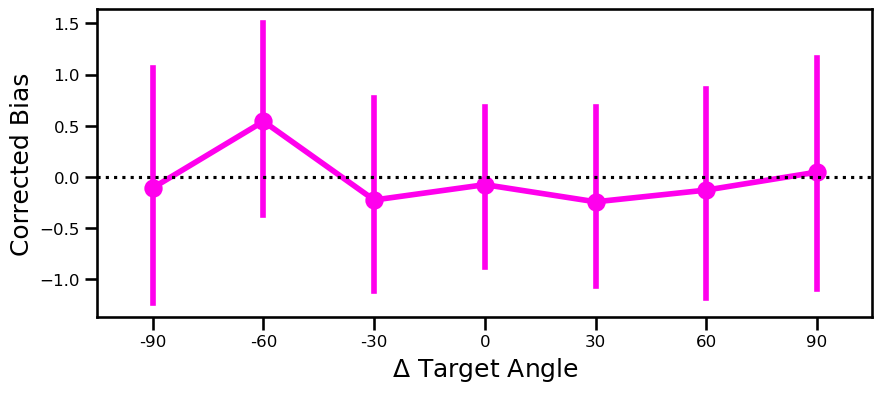

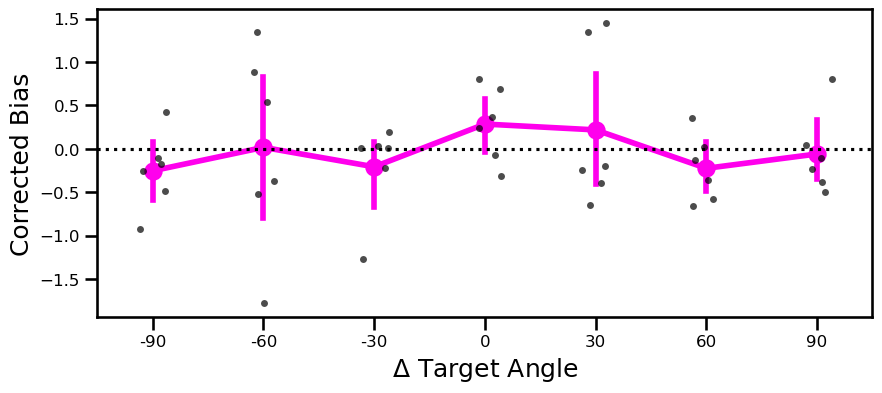

In [37]:
subject_means_repulse = (
    df_repulse
    .groupby(['SN', 'target_angle_diff'])['corrected_bias_repulse_theta_pv' ]
    .mean()
    .reset_index()
)

## INDIVIDUAL SUBJECT 
fig, ax = plt.subplots(figsize=(10,4))
sns.pointplot(
    data = df_repulse.loc[df_repulse["SN"] == 11],
    x='target_angle_diff',
    y='corrected_bias_repulse_theta_pv',
    estimator='mean',
    errorbar=('ci',95),
    #color='black',
    ax=ax
)
ax.axhline(0, color='black', linestyle=':')
ax.tick_params(axis='x', labelsize=12)
ax.tick_params(axis='y', labelsize=12)
plt.xlabel(r'$\Delta$ Target Angle')
plt.ylabel('Corrected Bias')

## GROUP DATA 
fig2, ax2 = plt.subplots(figsize=(10,4))
sns.pointplot(
    data=subject_means_repulse,
    x='target_angle_diff',
    y='corrected_bias_repulse_theta_pv',
    estimator='mean',
    errorbar=('ci',95),
    #color='black',
    ax=ax2
)
sns.stripplot(
    data=subject_means_repulse,
    x='target_angle_diff',
    y='corrected_bias_repulse_theta_pv',
    color='black',
    alpha=0.7,
    jitter=0.15,
    size=5,
    ax=ax2
)
ax2.axhline(0, color='black', linestyle=':')
ax2.tick_params(axis='x', labelsize=12)
ax2.tick_params(axis='y', labelsize=12)
plt.xlabel(r'$\Delta$ Target Angle')
plt.ylabel('Corrected Bias')


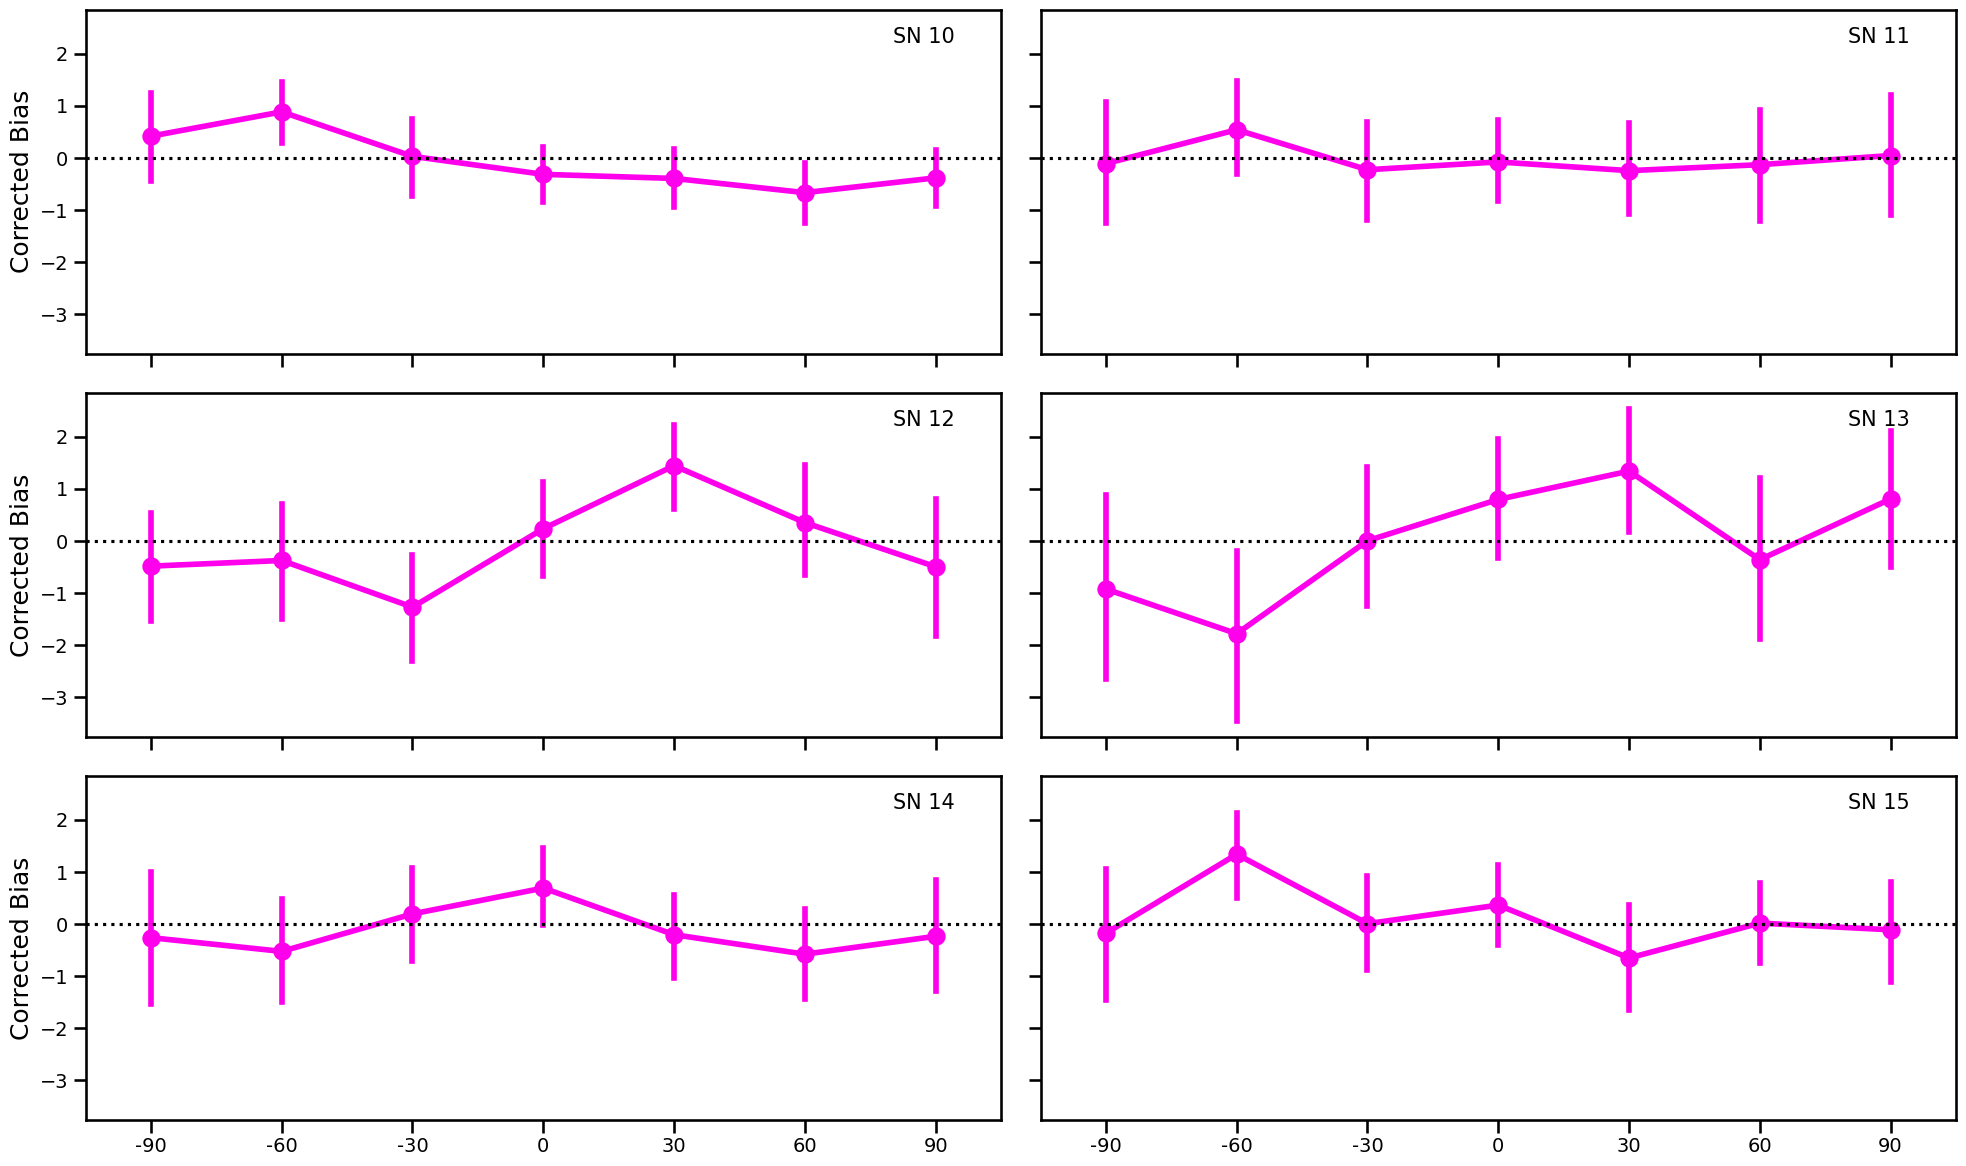

In [38]:
fig, axes = plt.subplots(3, 2, figsize=(20, 12), sharex=True, sharey=True)
axes = axes.flatten()

for ax, subject_num in zip(axes, PARTICIPANTS):

    sns.pointplot(
        data=df_repulse[df_repulse['SN'] == subject_num],
        x='target_angle_diff',
        y='corrected_bias_repulse_theta_pv',
        estimator='mean',
        errorbar=('ci', 95),
        ax=ax
    )

    ax.axhline(0, color='black', linestyle=':')
    ax.tick_params(axis='x', labelsize=14)
    ax.tick_params(axis='y', labelsize=14)

    ax.set_ylabel('Corrected Bias')
    ax.set_xlabel('')

    ax.text(
        0.95, 0.95,
        f'SN {subject_num}',
        transform=ax.transAxes,
        ha='right',
        va='top',
        fontsize=15
    )

# remove unused subplot(s)
for ax in axes[len(PARTICIPANTS):]:
    ax.remove()

plt.tight_layout()
plt.show()

# Plot UDL Phase 

Text(0, 0.5, 'Corrected Bias')

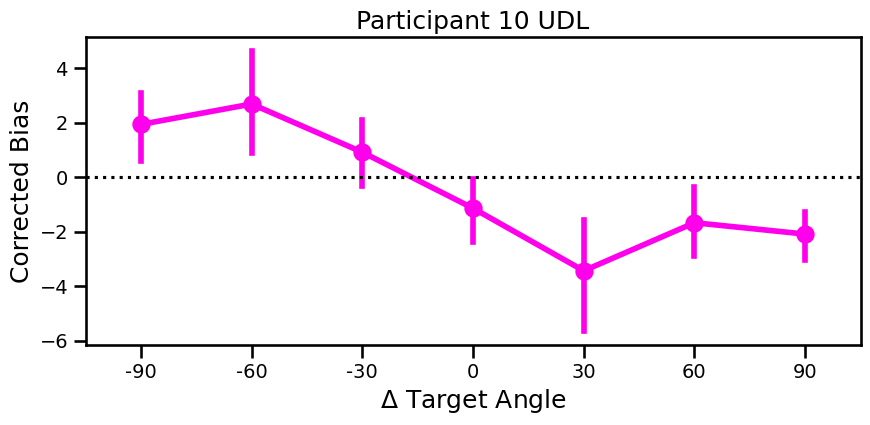

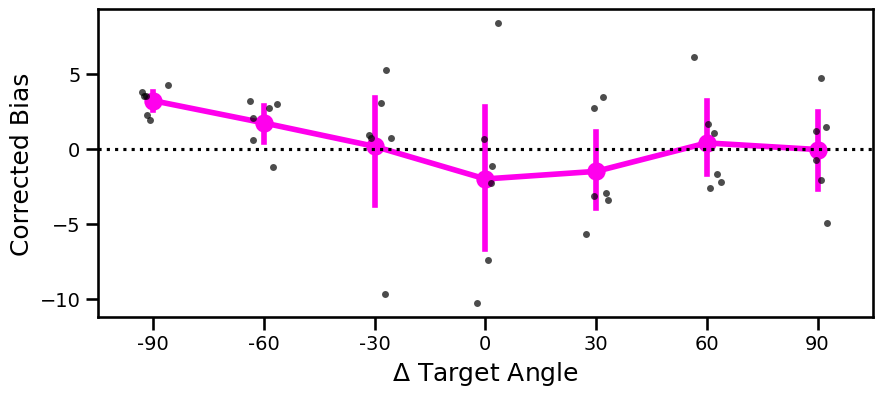

In [39]:
subject_means = df_udl_constrained.groupby(['SN', 'target_angle_diff'])['corrected_bias_udl_theta_pv'].mean().reset_index()

# plot graph for one participant
subject_num = 10
fig, ax = plt.subplots(figsize=(10,4))
sns.pointplot(
    data=df_udl_constrained[df_udl_constrained['SN']==subject_num],
    x='target_angle_diff',
    y='corrected_bias_udl_theta_pv',
    estimator='mean',
    errorbar=('ci',95),
    #color='black',
    ax=ax
)
ax.axhline(0, color='black', linestyle=':')
ax.tick_params(axis='x', labelsize=14)
ax.tick_params(axis='y', labelsize=14)
plt.xlabel(r'$\Delta$ Target Angle')
plt.ylabel('Corrected Bias') 
plt.title(f'Participant {subject_num} UDL')


# plot graph for group level 
fig, ax = plt.subplots(figsize=(10,4))
sns.pointplot(
    data=subject_means,
    x='target_angle_diff',
    y='corrected_bias_udl_theta_pv',
    estimator='mean',
    errorbar=('ci',95),
    #color='black',
    ax=ax
)

sns.stripplot(
    data=subject_means,
    x='target_angle_diff',
    y='corrected_bias_udl_theta_pv',
    color='black',
    alpha=0.7,
    jitter=0.15,
    size=5,
    ax=ax
)

ax.axhline(0, color='black', linestyle=':')
ax.tick_params(axis='x', labelsize=14)
ax.tick_params(axis='y', labelsize=14)
plt.xlabel(r'$\Delta$ Target Angle')
## change the name of the x axis 
plt.ylabel('Corrected Bias') 

# plt.savefig('withFB.png', dpi=600, bbox_inches='tight')

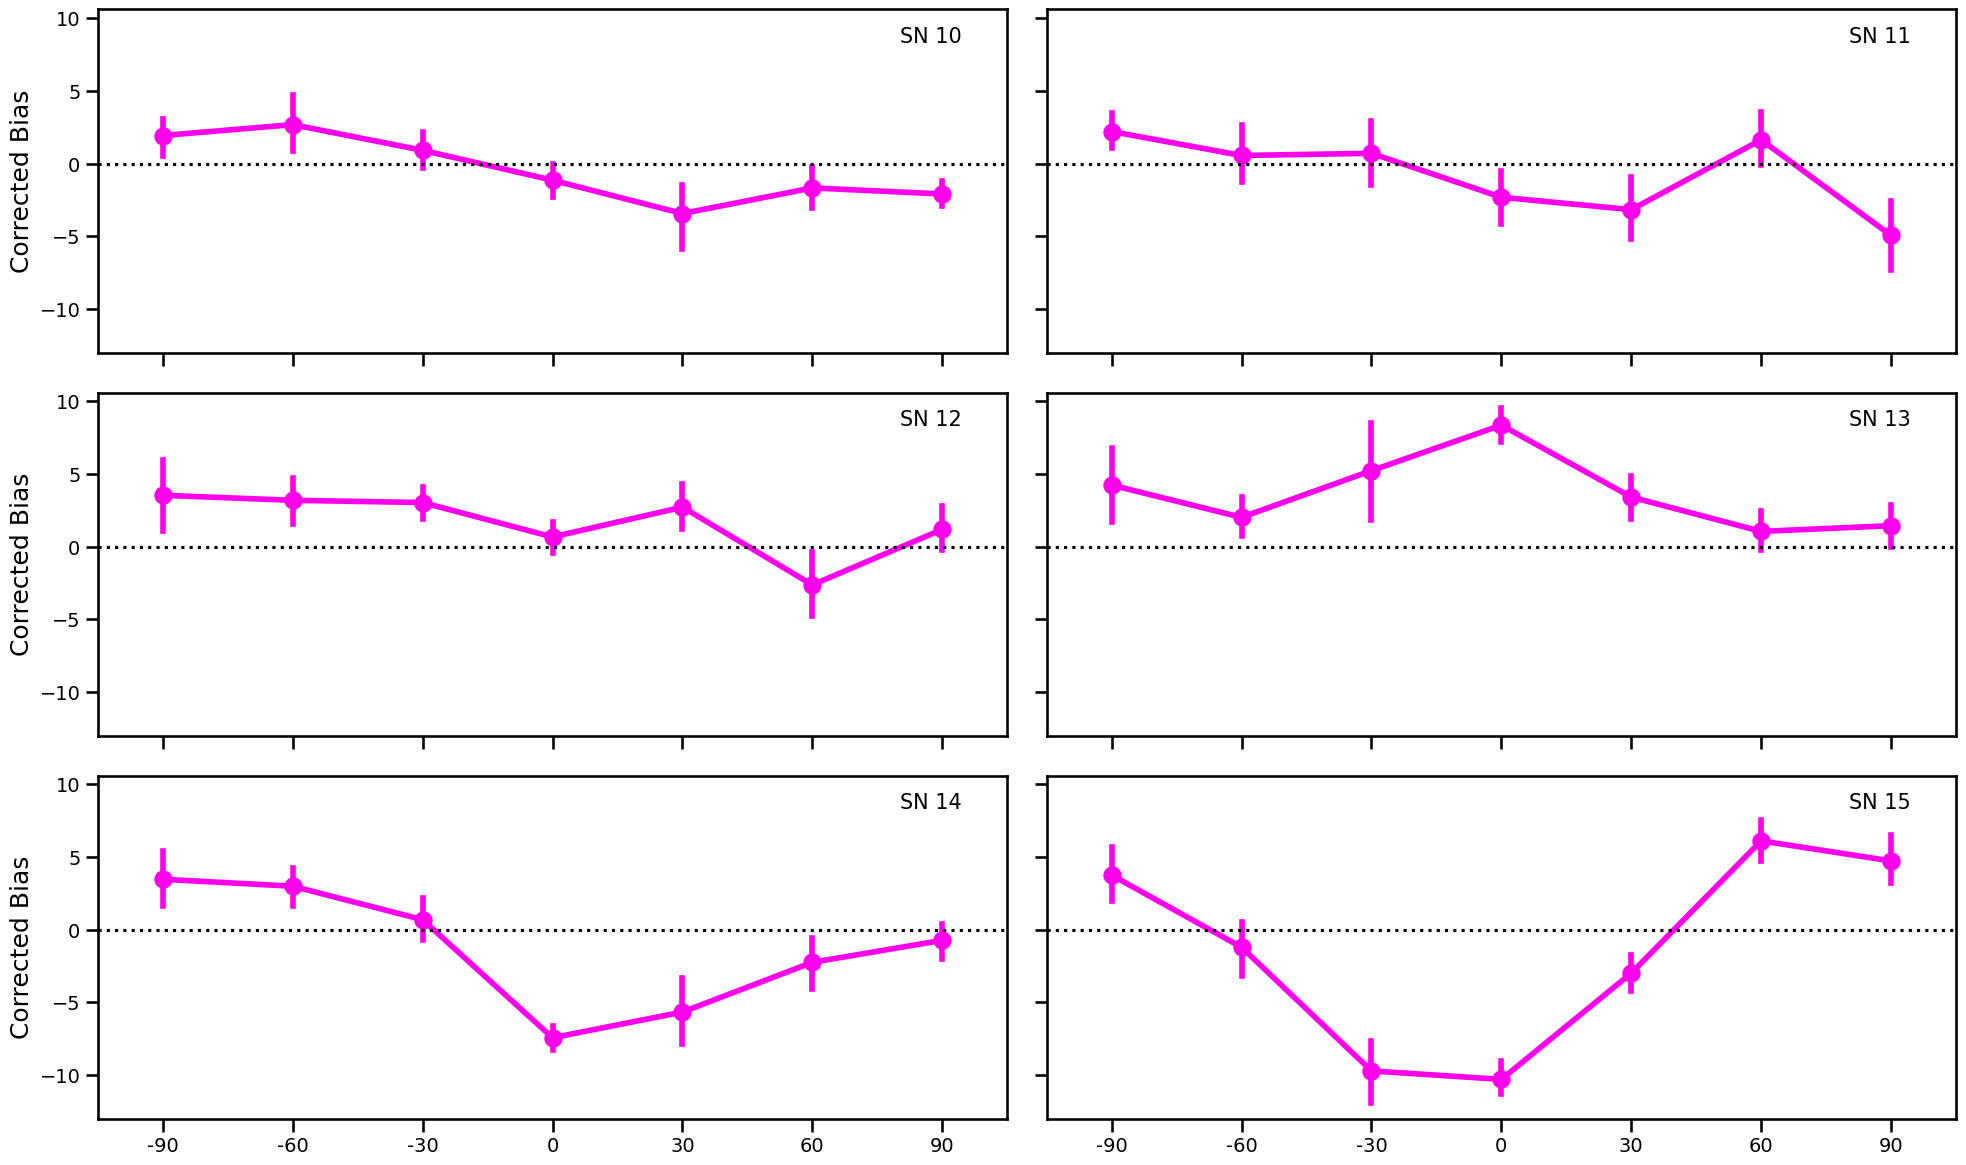

In [40]:
participants = sorted(df_udl_constrained['SN'].unique())

fig, axes = plt.subplots(3, 2, figsize=(20, 12), sharex=True, sharey=True)
axes = axes.flatten()

for ax, subject_num in zip(axes, participants):

    sns.pointplot(
        data=df_udl_constrained[df_udl_constrained['SN'] == subject_num],
        x='target_angle_diff',
        y='corrected_bias_udl_theta_pv', 
        estimator='mean',
        errorbar=('ci', 95),
        ax=ax
    )

    ax.axhline(0, color='black', linestyle=':')
    ax.tick_params(axis='x', labelsize=14)
    ax.tick_params(axis='y', labelsize=14)

    ax.set_ylabel('Corrected Bias')
    ax.set_xlabel('')

    ax.text(
        0.95, 0.95,
        f'SN {subject_num}',
        transform=ax.transAxes,
        ha='right',
        va='top',
        fontsize=15
    )

# remove unused subplot(s)
for ax in axes[len(participants):]:
    ax.remove()

plt.tight_layout()
plt.show()